# Categorical Data Analysis

## What is categorical data?
Categorical data represents groups, labels, or types rather than numerical measurements.

#### Examples from your dataset:
- Country — country names.
- StockCode — product codes.
- Description — product descriptions.
- InvoiceNo — invoice identifiers.
- CustomerID — customer identifiers.
#### Categorical data can be divided into two main types:
- Nominal: Categories without a natural order, such as Country.
- Ordinal: Categories with a meaningful order, such as Low, Medium, and High.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv", encoding="cp1252")

print("Dataset shape:", df.shape)
display(df.head())

categorical_columns = [
    "Country",
    "StockCode",
    "Description",
    "InvoiceNo",
    "CustomerID"
]

print(df[categorical_columns].dtypes)

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Country            str
StockCode          str
Description        str
InvoiceNo          str
CustomerID     float64
dtype: object


## Unique categories
Unique categories are the distinct values present in a categorical column.

For example, the Country column may contain many invoice rows but fewer distinct country names.

In [2]:
for column in ["Country", "StockCode", "Description"]:
    print(f"\n{column}")
    print("Number of unique categories:", df[column].nunique())
    print(df[column].dropna().unique()[:10])


Country
Number of unique categories: 38
<ArrowStringArray>
['United Kingdom',         'France',      'Australia',    'Netherlands',
        'Germany',         'Norway',           'EIRE',    'Switzerland',
          'Spain',         'Poland']
Length: 10, dtype: str

StockCode
Number of unique categories: 4070
<ArrowStringArray>
['85123A',  '71053', '84406B', '84029G', '84029E',  '22752',  '21730',
  '22633',  '22632',  '84879']
Length: 10, dtype: str

Description
Number of unique categories: 4223
<ArrowStringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',       'ASSORTED COLOUR BIRD ORNAMENT']
Length: 10, dtype: str


## Category frequencies
Category frequency tells us how often each category appears.

### Example
We can count how many records belong to each country.

In [4]:
country_counts = df["Country"].value_counts()

print(country_counts.head(10))

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64


## Category distribution
A category distribution shows the proportion of records belonging to each category.

### Example:
What percentage of all records belong to each of the most common countries?

In [5]:
country_distribution = (
    df["Country"]
    .value_counts(normalize=True)
    .mul(100)
)

print(country_distribution.head(10).round(2))

Country
United Kingdom    91.43
Germany            1.75
France             1.58
EIRE               1.51
Spain              0.47
Netherlands        0.44
Belgium            0.38
Switzerland        0.37
Portugal           0.28
Australia          0.23
Name: proportion, dtype: float64


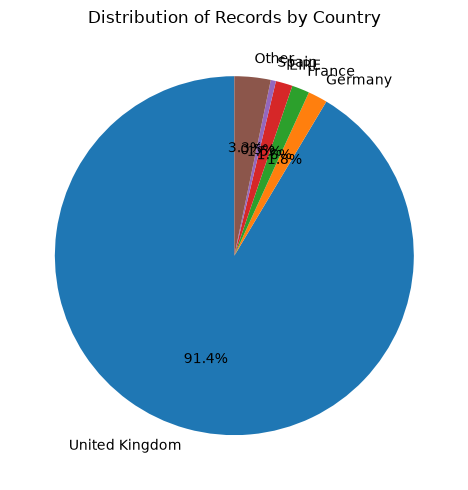

In [6]:
counts = df["Country"].value_counts()

top5 = counts.head(5)
other_count = counts.iloc[5:].sum()

plot_counts = pd.concat([
    top5,
    pd.Series({"Other": other_count})
])

plt.figure(figsize=(8, 5))
plt.pie(
    plot_counts,
    labels=plot_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Records by Country")
plt.tight_layout()
plt.show()

## Rare categories
A rare category is a category that occurs infrequently compared with the rest of the data.

### Example:
A country with very few retail records may be considered rare for a particular analysis.

In [7]:
country_counts = df["Country"].value_counts()

rare_countries = country_counts[country_counts < 100]

print("Number of rare country categories:", len(rare_countries))
print(rare_countries)

Number of rare country categories: 9
Country
United Arab Emirates    68
European Community      61
RSA                     58
Lebanon                 45
Lithuania               35
Brazil                  32
Czech Republic          30
Bahrain                 19
Saudi Arabia            10
Name: count, dtype: int64


## High cardinality and low cardinality
Cardinality means the number of distinct categories in a column.
- Low cardinality: A small number of distinct values.
- High cardinality: A large number of distinct values.

In [8]:
categorical_columns = [
    "Country",
    "StockCode",
    "Description",
    "InvoiceNo",
    "CustomerID"
]

cardinality_summary = pd.DataFrame({
    "Unique_Categories": {
        col: df[col].nunique()
        for col in categorical_columns
    },
    "Missing_Values": {
        col: df[col].isna().sum()
        for col in categorical_columns
    }
})

cardinality_summary["Cardinality_Type"] = np.where(
    cardinality_summary["Unique_Categories"] <= 10,
    "Low",
    np.where(
        cardinality_summary["Unique_Categories"] <= 50,
        "Medium",
        "High"
    )
)

display(cardinality_summary.sort_values(
    "Unique_Categories",
    ascending=False
))

,Unique_Categories,Missing_Values,Cardinality_Type
InvoiceNo,25900,0,High
CustomerID,4372,135080,High
Description,4223,1454,High
StockCode,4070,0,High
Country,38,0,Medium


## Category imbalance
Category imbalance occurs when some categories appear much more frequently than others.

### Example:
If one country accounts for most of the records and several countries have very few, the distribution is imbalanced.

In [9]:
country_counts = df["Country"].value_counts()

print("Most frequent category:")
print(country_counts.head(1))

print("\nLeast frequent categories:")
print(country_counts.tail(10))

Most frequent category:
Country
United Kingdom    495478
Name: count, dtype: int64

Least frequent categories:
Country
Malta                   127
United Arab Emirates     68
European Community       61
RSA                      58
Lebanon                  45
Lithuania                35
Brazil                   32
Czech Republic           30
Bahrain                  19
Saudi Arabia             10
Name: count, dtype: int64


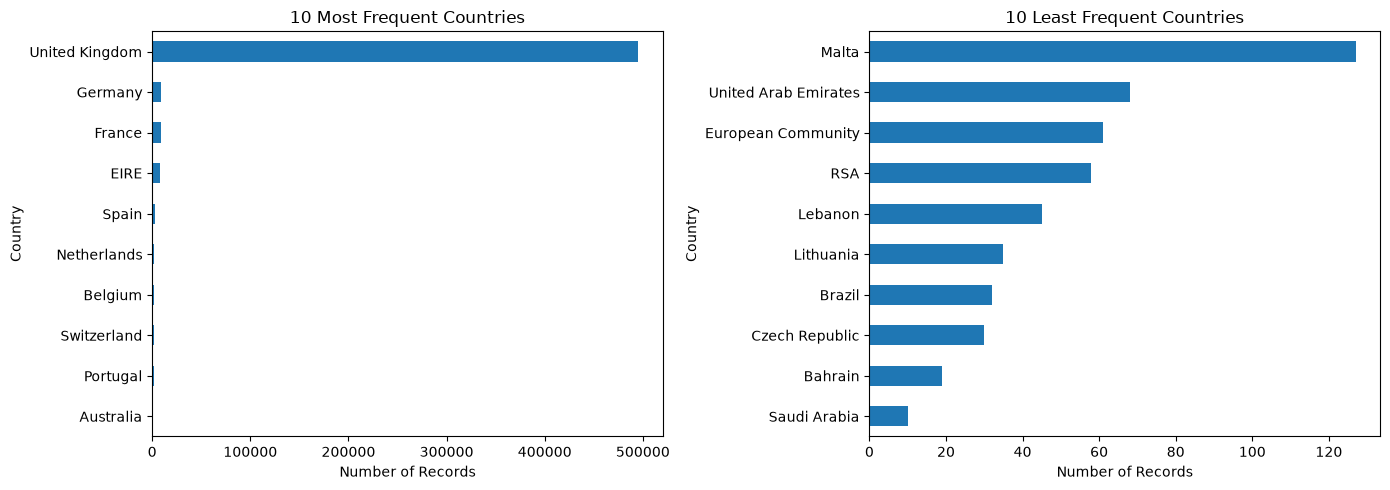

In [10]:
counts = df["Country"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts.head(10).sort_values().plot(
    kind="barh",
    ax=axes[0],
    title="10 Most Frequent Countries"
)

counts.tail(10).sort_values().plot(
    kind="barh",
    ax=axes[1],
    title="10 Least Frequent Countries"
)

axes[0].set_xlabel("Number of Records")
axes[1].set_xlabel("Number of Records")

plt.tight_layout()
plt.show()